In [13]:
import numpy as np
import matplotlib.pyplot as plt
import h5py as h5
import emcee
import torch
import sacc
import corner
import os
import itertools
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy.stats import qmc
from IPython.display import clear_output

from copy import deepcopy

import src.training as training
import src.models as models

from multiprocessing import Pool, cpu_count
from time import time
from importlib import reload
reload(training)
reload(models)

seed = 14
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)

# set device for all tensors
device = 'cuda'

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['cmr10']
plt.rcParams['mathtext.fontset'] ='cm'
plt.rcParams['figure.facecolor'] = 'white'
plt.rc('axes', unicode_minus=False)
plt.rc('axes.formatter', use_mathtext=True)

In [14]:
# load results
fname = 'results/maml_compare_pretrained_nsamps=40_nsmooth=20.h5'
with h5.File(fname, 'r') as f:
    pretrain_times = f['pretrain_times'][:]
    pretrain_mapes = f['pretrain_mapes'][:]
    pretrain_frates = f['pretrain_frates'][:]
    maml_times = f['maml_times'][:]
    maml_mapes = f['maml_mapes'][:]
    maml_frates = f['maml_frates'][:]
    seeds = f['seeds'][:]

n_samples = np.linspace(10, 1000, 40).astype(int)
print(n_samples)

[  10   35   60   86  111  136  162  187  213  238  263  289  314  340
  365  390  416  441  466  492  517  543  568  593  619  644  670  695
  720  746  771  796  822  847  873  898  923  949  974 1000]


0.26317124141667986 0.22237644369582193


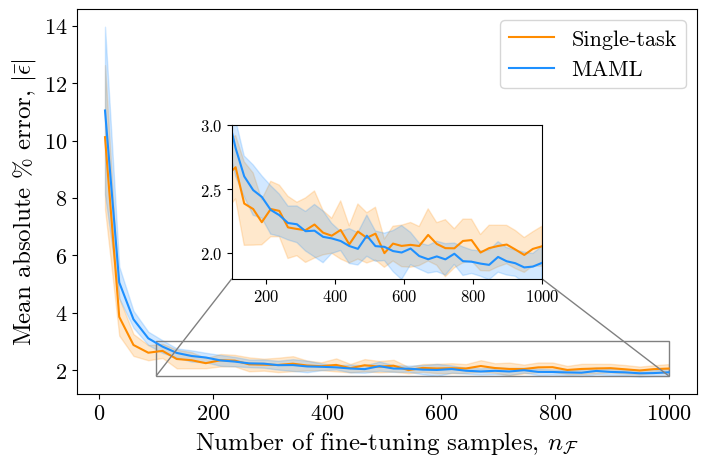

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# Compute mean and std of MAPEs
pt_mapes_mean = np.mean(pretrain_mapes, axis=1)
pt_mapes_std = np.std(pretrain_mapes, axis=1)
maml_mapes_mean = np.mean(maml_mapes, axis=1)
maml_mapes_std = np.std(maml_mapes, axis=1)

print(np.mean(pt_mapes_std), np.mean(maml_mapes_std))

fig, ax = plt.subplots(figsize=(8, 5))

# Main plot
ax.plot(n_samples, pt_mapes_mean, label=r'Single-task', color='darkorange')
ax.fill_between(
    n_samples,
    pt_mapes_mean - pt_mapes_std,
    pt_mapes_mean + pt_mapes_std,
    alpha=0.2,
    color='darkorange'
)

ax.plot(n_samples, maml_mapes_mean, label=r'MAML', color='dodgerblue')
ax.fill_between(
    n_samples,
    maml_mapes_mean - maml_mapes_std,
    maml_mapes_mean + maml_mapes_std,
    alpha=0.2,
    color='dodgerblue'
)

ax.set_xlabel(r'Number of fine-tuning samples, $n_\mathcal{F}$', fontsize=18)
ax.set_ylabel(r'Mean absolute % error, $|\bar{\epsilon}|$', fontsize=18)
ax.tick_params(labelsize=16)
ax.legend(fontsize=16)

# Create inset axes
axins = inset_axes(ax, width="50%", height="40%", loc='center')  # Adjust position as needed

# Plot inset zoomed region
axins.plot(n_samples, pt_mapes_mean, color='darkorange')
axins.fill_between(
    n_samples,
    pt_mapes_mean - pt_mapes_std,
    pt_mapes_mean + pt_mapes_std,
    alpha=0.2,
    color='darkorange'
)
axins.tick_params(labelsize=12)
#axins.set_xticks([])

axins.plot(n_samples, maml_mapes_mean, color='dodgerblue')
axins.fill_between(
    n_samples,
    maml_mapes_mean - maml_mapes_std,
    maml_mapes_mean + maml_mapes_std,
    alpha=0.2,
    color='dodgerblue'
)

# Set zoom-in region to focus on x values between 100 and 1000
axins.set_xlim(100, 1000)
axins.set_ylim(1.8, 3.0)

# Indicate zoom region
mark_inset(ax, axins, loc1=3, loc2=4, fc="none", ec="0.5", )

# Save figure
plt.savefig('plots/maml_vs_pretrain_mapes.pdf', bbox_inches='tight')

plt.show()

0.09704207653770605 0.0708361910943128


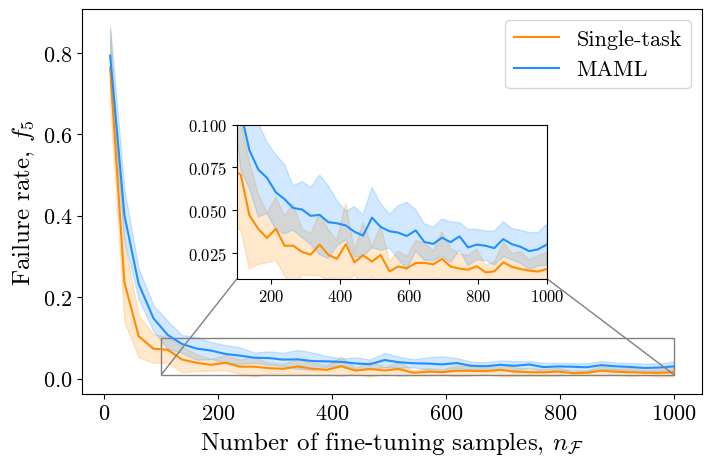

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# Compute mean and std of failure rates
pt_frates_mean = np.mean(pretrain_frates, axis=1)
pt_frates_std = np.std(pretrain_frates, axis=1)
maml_frates_mean = np.mean(maml_frates, axis=1)
maml_frates_std = np.std(maml_frates, axis=1)

print(np.max(pt_frates_std), np.max(maml_frates_std))

fig, ax = plt.subplots(figsize=(8, 5))

# Main plot
ax.plot(n_samples, pt_frates_mean, label=r'Single-task', color='darkorange')
ax.fill_between(
    n_samples,
    np.maximum(pt_frates_mean - pt_frates_std, 0),
    pt_frates_mean + pt_frates_std,
    alpha=0.2,
    color='darkorange'
)

ax.plot(n_samples, maml_frates_mean, label=r'MAML', color='dodgerblue')
ax.fill_between(
    n_samples,
    np.maximum(maml_frates_mean - maml_frates_std, 0),
    maml_frates_mean + maml_frates_std,
    alpha=0.2,
    color='dodgerblue'
)

# ax.set_yscale('log')
# ax.set_ylim([0,1])
ax.set_xlabel(r'Number of fine-tuning samples, $n_\mathcal{F}$', fontsize=18)
ax.set_ylabel(r'Failure rate, $f_{5}$', fontsize=18)
ax.tick_params(labelsize=16)
ax.legend(fontsize=16)

# Create inset axes
axins = inset_axes(ax, width="50%", height="40%", loc='center')  # Adjust position as needed

# Plot inset zoomed region
axins.plot(n_samples, pt_frates_mean, color='darkorange')
axins.fill_between(
    n_samples,
    np.maximum(pt_frates_mean - pt_frates_std, 0),
    pt_frates_mean + pt_frates_std,
    alpha=0.2,
    color='darkorange'
)

axins.plot(n_samples, maml_frates_mean, color='dodgerblue')
axins.fill_between(
    n_samples,
    np.maximum(maml_frates_mean - maml_frates_std, 0),
    maml_frates_mean + maml_frates_std,
    alpha=0.2,
    color='dodgerblue'
)

# Set zoom-in region to focus on x values between 100 and 1000
axins.set_xlim(100, 1000)
axins.set_ylim(0.01, 0.1)

# Remove x ticks and adjust y tick size in inset
axins.tick_params(labelsize=12)  # Increase y-axis tick size

# Indicate zoom region
mark_inset(ax, axins, loc1=3, loc2=4, fc="none", ec="0.5")

# Save figure
plt.savefig('plots/maml_vs_pretrain_frates.pdf', bbox_inches='tight')

plt.show()